In [ ]:
--# Basic Libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score

# KNN Model
from sklearn.neighbors import KNeighborsClassifier

# Evaluation
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
# Load dataset
glass = pd.read_csv('/content/glass.csv')

# Display first 5 rows
glass.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [ ]:
glass.info()

glass.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


In [ ]:
#Business Problem
'''Business Objective

A glass manufacturing company wants to automate the classification of glass types based on chemical composition.

Business Constraint
Wrong classification may affect production quality.
Model should provide high accuracy.'''

'Business Objective\n\nA glass manufacturing company wants to automate the classification of glass types based on chemical composition.\n\nBusiness Constraint\nWrong classification may affect production quality.\nModel should provide high accuracy.'

In [ ]:
glass.columns

Index(['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type'], dtype='object')

In [ ]:
'''feature   description
RI         refractive index
Na         Sodium
Mg         Magnesium
Al         Aluminium
Si         Silicon
K          Potassium
Ca         Calcium
Ba         Barium
Fe         Iron
Type       Types of glass(target var)
Glass_type Type of glass:
1 building_windows_float_processed
2 building_windows_non_float_processed
3 vehicle_windows_float_processed
4 vehicle_windows_non_float_processed (none in this database)
5 containers
6 tableware
7 headlamps'''

'feature   description\nRI         refractive index\nNa         Sodium\nMg         Magnesium\nAl         Aluminium\nSi         Silicon\nK          Potassium\nCa         Calcium\nBa         Barium\nFe         Iron\nType       Types of glass(target var)\nGlass_type Type of glass:\n1 building_windows_float_processed\n2 building_windows_non_float_processed\n3 vehicle_windows_float_processed\n4 vehicle_windows_non_float_processed (none in this database)\n5 containers\n6 tableware\n7 headlamps'

In [ ]:
#missing val
glass.isnull().sum()

#duplicate val
glass.duplicated().sum()

np.int64(1)

In [ ]:
#EDA
glass.describe().T

,count,mean,std,min,25%,50%,75%,max
RI,214.0,1.518365,0.003037,1.51115,1.516522,1.51768,1.519157,1.53393
Na,214.0,13.407850,0.816604,10.73000,12.907500,13.30000,13.825000,17.38000
Mg,214.0,2.684533,1.442408,0.00000,2.115000,3.48000,3.600000,4.49000
Al,214.0,1.444907,0.499270,0.29000,1.190000,1.36000,1.630000,3.50000
Si,214.0,72.650935,0.774546,69.81000,72.280000,72.79000,73.087500,75.41000
K,214.0,0.497056,0.652192,0.00000,0.122500,0.55500,0.610000,6.21000
Ca,214.0,8.956963,1.423153,5.43000,8.240000,8.60000,9.172500,16.19000
Ba,214.0,0.175047,0.497219,0.00000,0.000000,0.00000,0.000000,3.15000
Fe,214.0,0.057009,0.097439,0.00000,0.000000,0.00000,0.100000,0.51000
Type,214.0,2.780374,2.103739,1.00000,1.000000,2.00000,3.000000,7.00000


In [ ]:
#1 MBD
glass.mean(numeric_only=True)

#2 MBD
glass.var(numeric_only=True)

glass.std(numeric_only=True)

#3MBD
glass.skew(numeric_only=True)

#4MBD
glass.kurt(numeric_only=True)

,0
RI,4.931737
Na,3.052232
Mg,-0.410319
Al,2.060569
Si,2.967903
K,54.689699
Ca,6.681978
Ba,12.541084
Fe,2.662016
Type,-0.279518


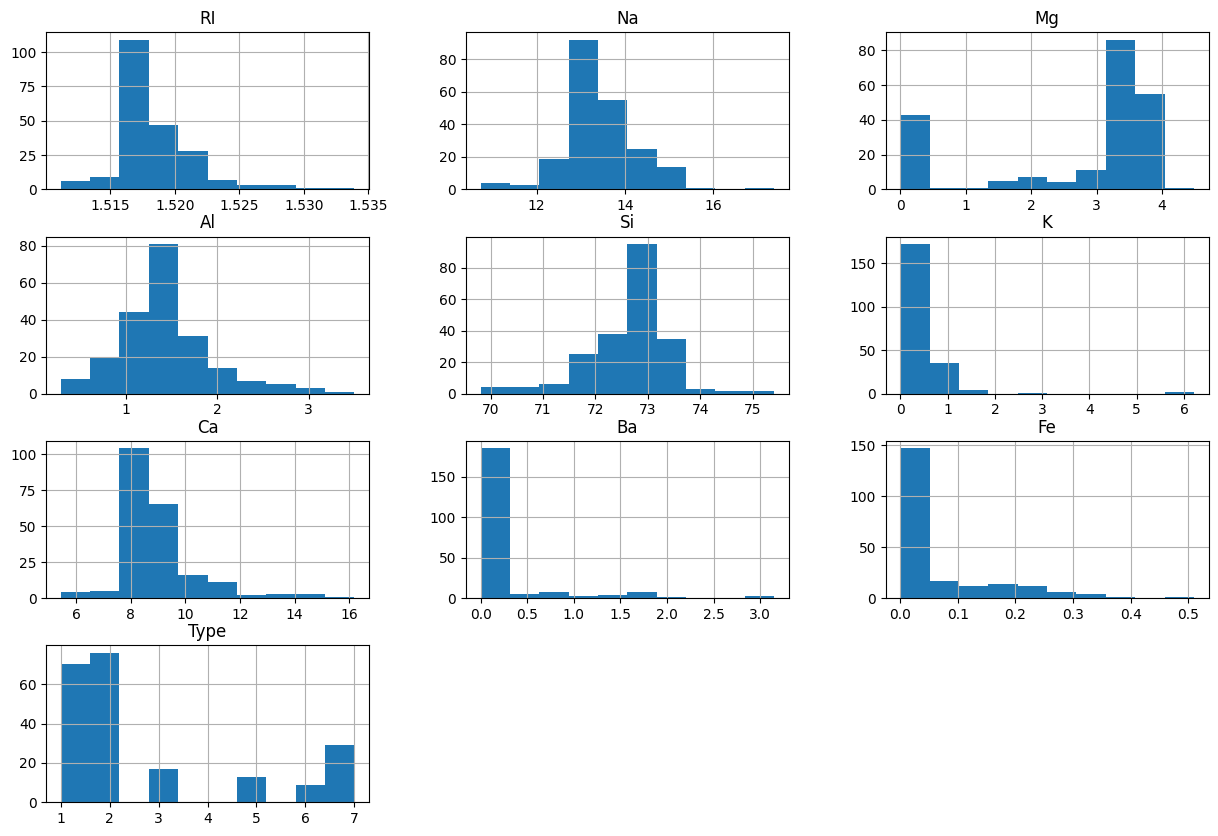

In [ ]:
#univariate analysis
glass.hist(figsize=(15,10))
plt.show()

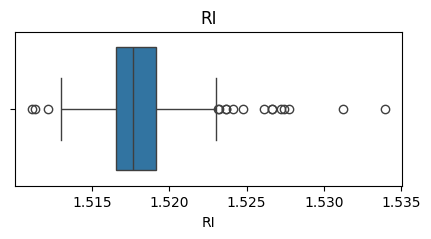

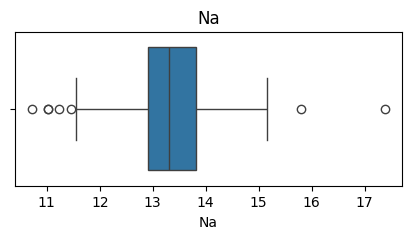

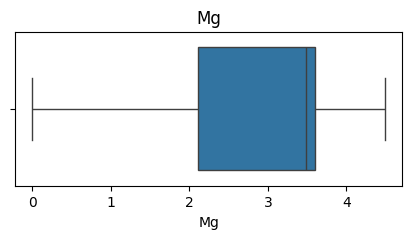

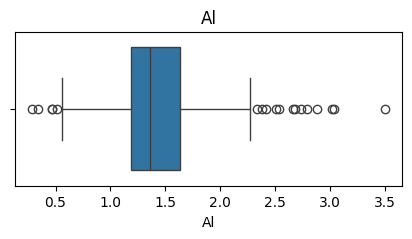

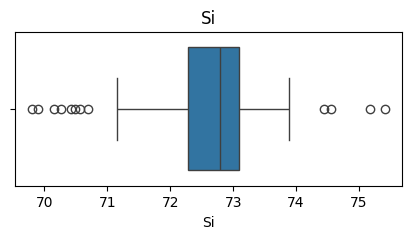

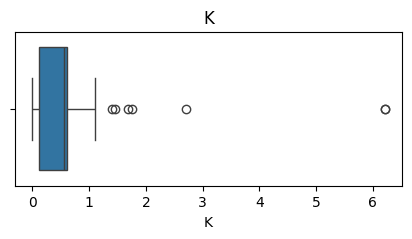

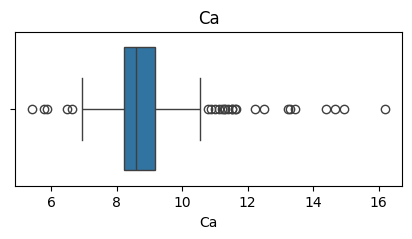

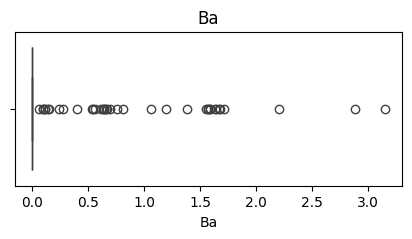

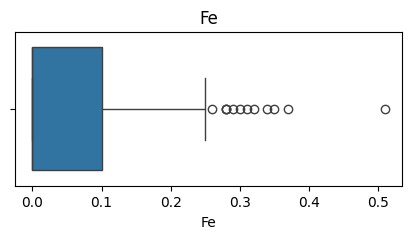

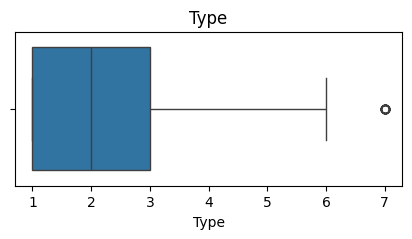

In [ ]:
#boxplot
for column in glass.columns:
    plt.figure(figsize=(5,2))
    sns.boxplot(x=glass[column])
    plt.title(column)
    plt.show()

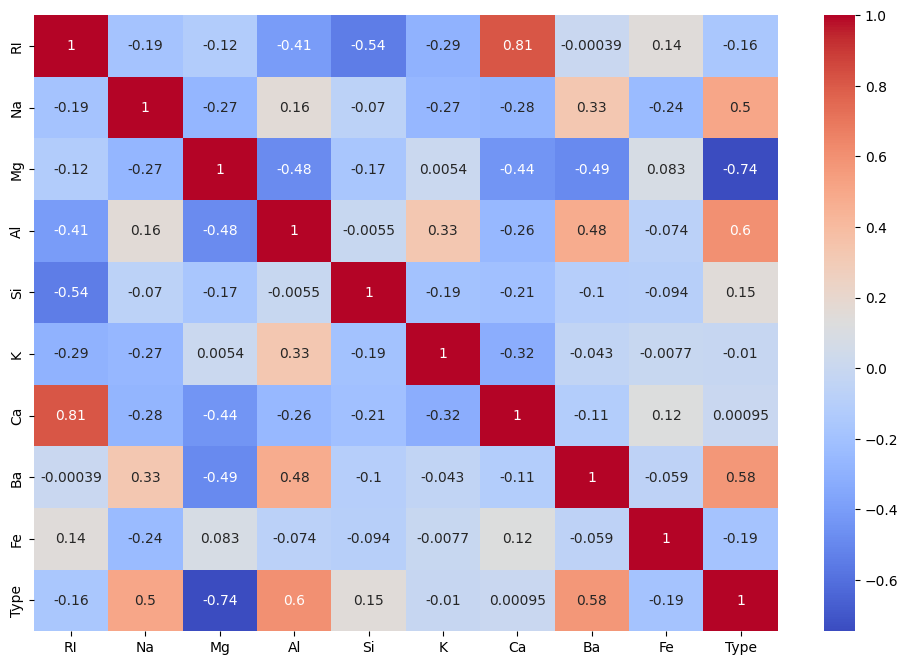

In [ ]:
#bivariate analysis
plt.figure(figsize=(12,8))
sns.heatmap(glass.corr(), annot=True, cmap='coolwarm')
plt.show()

In [ ]:
#feature and target separation
X = glass.drop('Type', axis=1)
y = glass['Type']

In [ ]:
#data scaling
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [ ]:
#train-test-split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
#optimun K value
train_acc = []
test_acc = []

for k in range(1,21):
    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train, y_train)

    train_acc.append(knn.score(X_train, y_train))
    test_acc.append(knn.score(X_test, y_test))

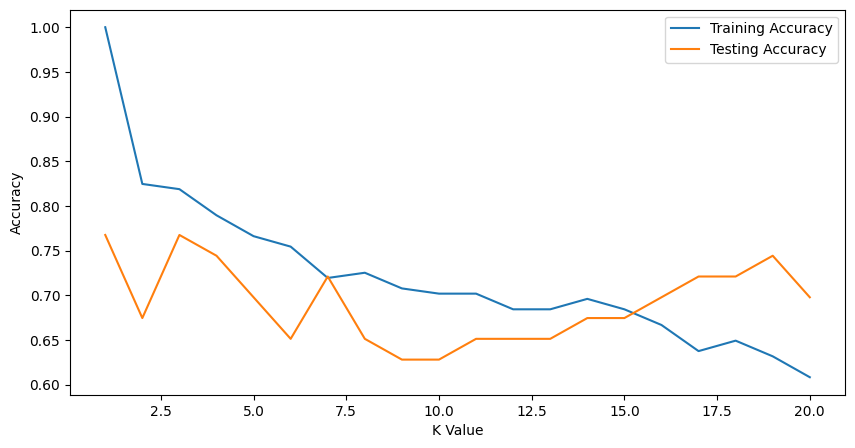

In [ ]:
#visualization of K
plt.figure(figsize=(10,5))

plt.plot(range(1,21), train_acc, label='Training Accuracy')
plt.plot(range(1,21), test_acc, label='Testing Accuracy')

plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
#final KNN model building
knn_final = KNeighborsClassifier(n_neighbors=3)

knn_final.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

In [ ]:
#prediction
y_pred = knn_final.predict(X_test)

In [ ]:
#evaluation
accuracy_score(y_test, y_pred)

0.7674418604651163

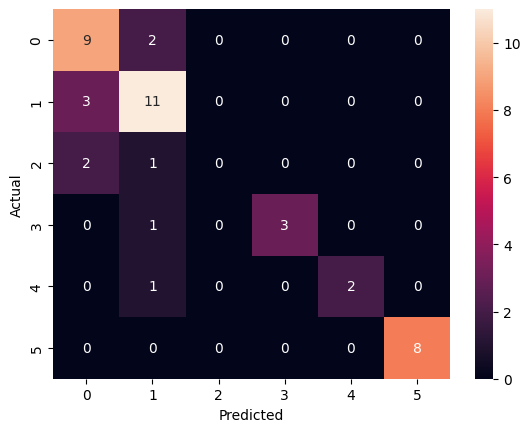

In [ ]:
#CM
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
#classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.64      0.82      0.72        11
           2       0.69      0.79      0.73        14
           3       0.00      0.00      0.00         3
           5       1.00      0.75      0.86         4
           6       1.00      0.67      0.80         3
           7       1.00      1.00      1.00         8

    accuracy                           0.77        43
   macro avg       0.72      0.67      0.69        43
weighted avg       0.74      0.77      0.74        43



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
#cross validation
cv_scores = cross_val_score(
    knn_final,
    X_scaled,
    y,
    cv=5
)

print(cv_scores)

print("Average CV Accuracy:", cv_scores.mean())

[0.65116279 0.74418605 0.55813953 0.58139535 0.71428571]
Average CV Accuracy: 0.6498338870431895


In [ ]:
#Model Interpretation
'''Interpretation
KNN classifies glass types based on nearest neighboring samples.
Scaling improves model performance.
Cross validation ensures model stability.'''

#Business Benefits
'''Reduces manual classification effort.
Faster production decisions.
Improves manufacturing quality.
Reduces human error.'''

'Reduces manual classification effort.\nFaster production decisions.\nImproves manufacturing quality.\nReduces human error.'

In [ ]:
#Assignment 2
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
zoo = pd.read_csv('/content/Zoo.csv')

zoo.head()

,animal name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,type
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1


In [ ]:
zoo.info()

zoo.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   animal name  101 non-null    object
 1   hair         101 non-null    int64 
 2   feathers     101 non-null    int64 
 3   eggs         101 non-null    int64 
 4   milk         101 non-null    int64 
 5   airborne     101 non-null    int64 
 6   aquatic      101 non-null    int64 
 7   predator     101 non-null    int64 
 8   toothed      101 non-null    int64 
 9   backbone     101 non-null    int64 
 10  breathes     101 non-null    int64 
 11  venomous     101 non-null    int64 
 12  fins         101 non-null    int64 
 13  legs         101 non-null    int64 
 14  tail         101 non-null    int64 
 15  domestic     101 non-null    int64 
 16  catsize      101 non-null    int64 
 17  type         101 non-null    int64 
dtypes: int64(17), object(1)
memory usage: 14.3+ KB


,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,type
count,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000
mean,0.425743,0.198020,0.584158,0.405941,0.237624,0.356436,0.554455,0.603960,0.821782,0.792079,0.079208,0.168317,2.841584,0.742574,0.128713,0.435644,2.831683
std,0.496921,0.400495,0.495325,0.493522,0.427750,0.481335,0.499505,0.491512,0.384605,0.407844,0.271410,0.376013,2.033385,0.439397,0.336552,0.498314,2.102709
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,1.000000
50%,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,4.000000,1.000000,0.000000,0.000000,2.000000
75%,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,4.000000,1.000000,0.000000,1.000000,4.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,8.000000,1.000000,1.000000,1.000000,7.000000


In [ ]:
#Business Problem
'''Business Objective

National Zoopark wants to automate animal classification based on characteristics.'''

#Business Constraints
'''Wrong classification may affect animal management.
Fast prediction required.'''

In [ ]:
zoo.columns

Index(['animal name', 'hair', 'feathers', 'eggs', 'milk', 'airborne',
       'aquatic', 'predator', 'toothed', 'backbone', 'breathes', 'venomous',
       'fins', 'legs', 'tail', 'domestic', 'catsize', 'type'],
      dtype='object')

In [ ]:
#data dictionary
'''features    description
    hair       has hair
    feathers   has feathers
    eges       gives eggs
    milk       gives milk
    airbone    can fly
    aquatic    aqua animal
    predator   predator
    toothed    has teeth
    backbone   has backbone
    breathes   breaths
    venomous   venomous
    fins       has fins
    legs       no of legs
    tail       has tail
    domestic   domestic animal
    catsize    cat sized
    type       animal type'''


In [ ]:
#missing val
zoo.isnull().sum()

,0
animal name,0
hair,0
feathers,0
eggs,0
milk,0
airborne,0
aquatic,0
predator,0
toothed,0
backbone,0


In [ ]:
#duplicate val
zoo.duplicated().sum()

np.int64(0)

In [ ]:
#summary stat
zoo.describe().T

,count,mean,std,min,25%,50%,75%,max
hair,101.0,0.425743,0.496921,0.0,0.0,0.0,1.0,1.0
feathers,101.0,0.198020,0.400495,0.0,0.0,0.0,0.0,1.0
eggs,101.0,0.584158,0.495325,0.0,0.0,1.0,1.0,1.0
milk,101.0,0.405941,0.493522,0.0,0.0,0.0,1.0,1.0
airborne,101.0,0.237624,0.427750,0.0,0.0,0.0,0.0,1.0
aquatic,101.0,0.356436,0.481335,0.0,0.0,0.0,1.0,1.0
predator,101.0,0.554455,0.499505,0.0,0.0,1.0,1.0,1.0
toothed,101.0,0.603960,0.491512,0.0,0.0,1.0,1.0,1.0
backbone,101.0,0.821782,0.384605,0.0,1.0,1.0,1.0,1.0
breathes,101.0,0.792079,0.407844,0.0,1.0,1.0,1.0,1.0


In [ ]:
#1MBD
zoo.mean(numeric_only=True)

#2MBD
zoo.var(numeric_only=True)
zoo.std(numeric_only=True)

#3MBD
zoo.skew(numeric_only=True)

#4MBD
zoo.kurt(numeric_only=True)



,0
hair,-1.945969
feathers,0.373997
eggs,-1.918204
milk,-1.886536
airborne,-0.442773
aquatic,-1.662967
predator,-1.990336
toothed,-1.850801
backbone,0.932321
breathes,0.137564


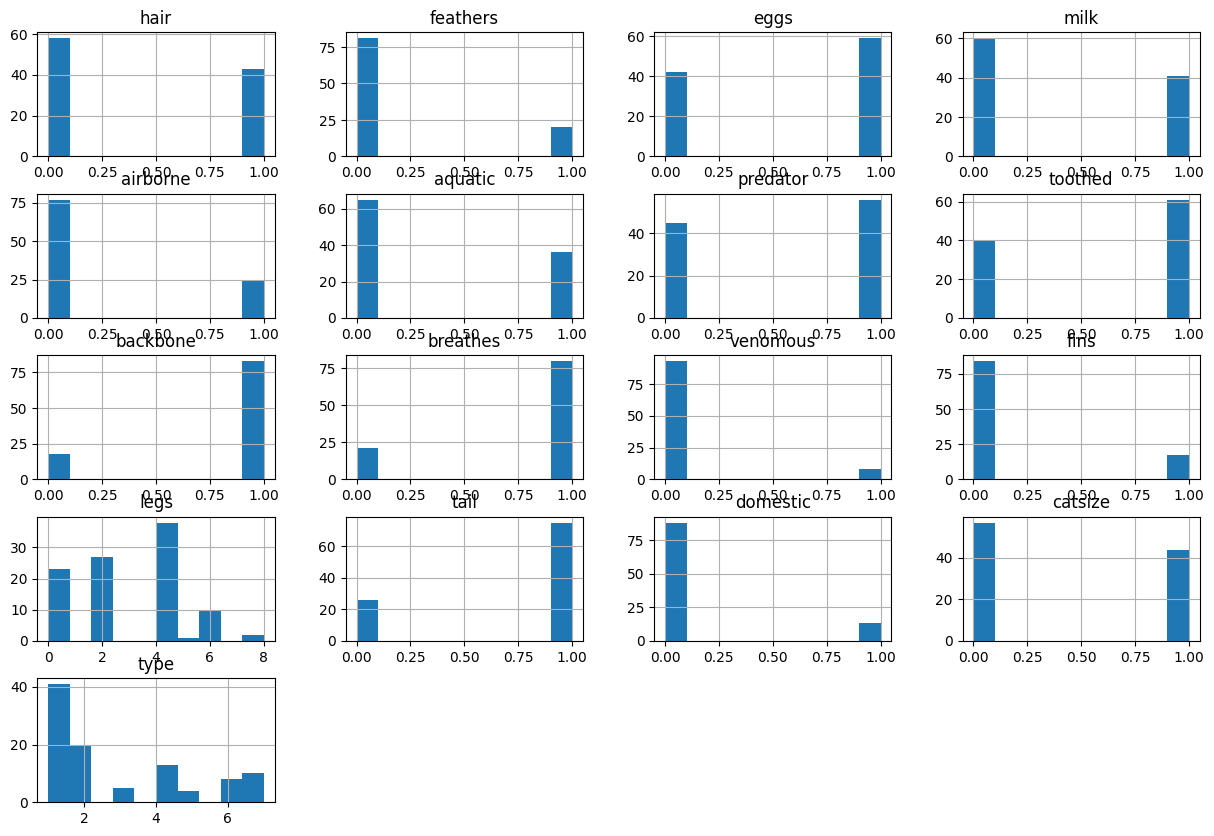

In [ ]:
#univarite analysis
zoo.hist(figsize=(15,10))
plt.show()

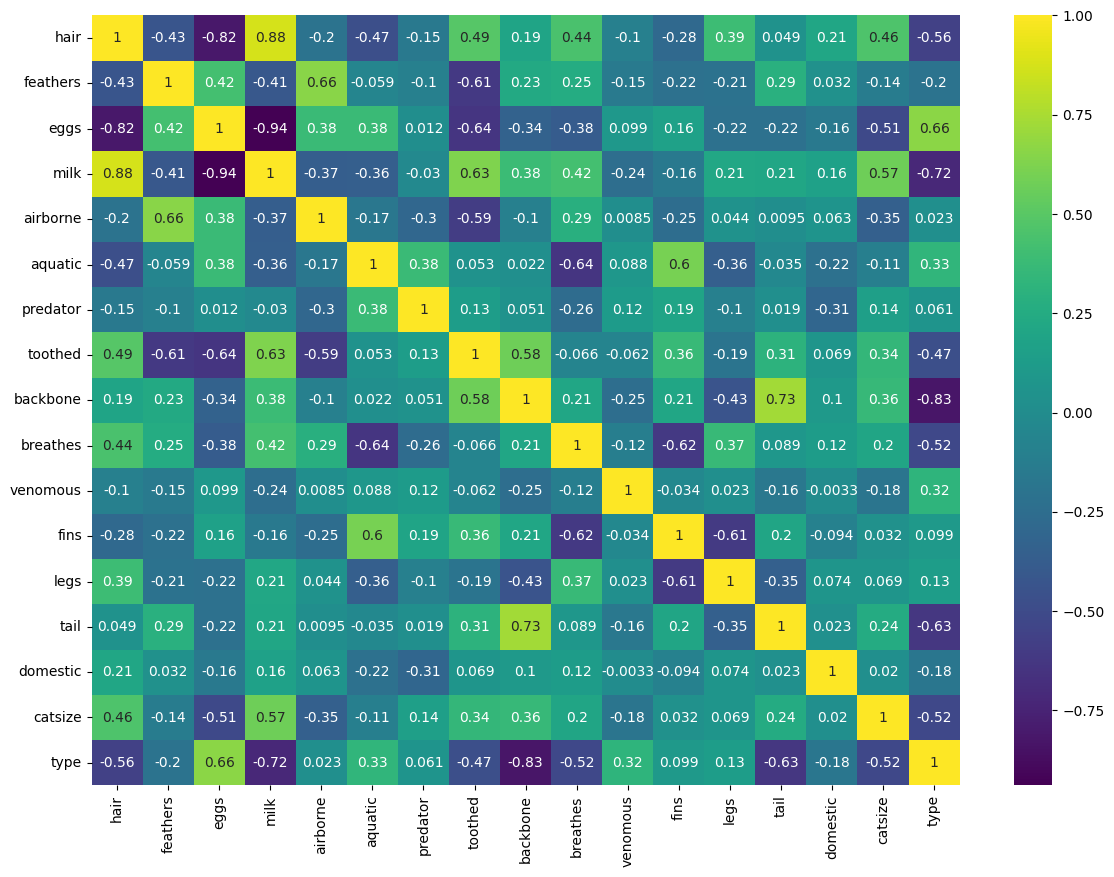

In [ ]:
plt.figure(figsize=(14,10))
sns.heatmap(zoo.drop('animal name', axis=1).corr(), annot=True, cmap='viridis')
plt.show()

In [ ]:
#features and target split
X = zoo.drop(['type','animal name'], axis=1)

y = zoo['type']

In [ ]:
#scaling
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [ ]:
#train-test-split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
#Best K
train_acc = []
test_acc = []

for k in range(1,21):

    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train, y_train)

    train_acc.append(knn.score(X_train, y_train))
    test_acc.append(knn.score(X_test, y_test))

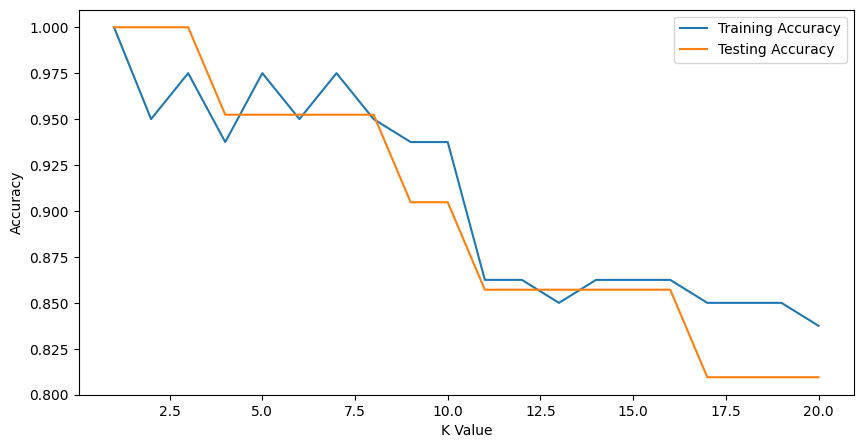

In [ ]:
#accuracy visualization
plt.figure(figsize=(10,5))

plt.plot(range(1,21), train_acc, label='Training Accuracy')
plt.plot(range(1,21), test_acc, label='Testing Accuracy')

plt.xlabel('K Value')
plt.ylabel('Accuracy')

plt.legend()
plt.show()

In [ ]:
#final KNN model
knn_final = KNeighborsClassifier(n_neighbors=5)

knn_final.fit(X_train, y_train)

KNeighborsClassifier()

In [ ]:
#prediction
y_pred = knn_final.predict(X_test)

In [ ]:
#evalustion
accuracy_score(y_test, y_pred)

0.9523809523809523

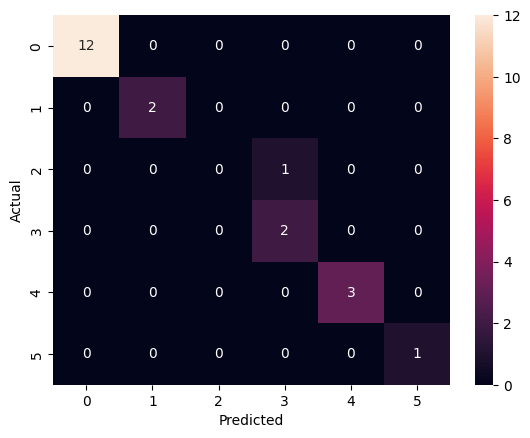

In [ ]:
#CM
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d')

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [ ]:
#classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      1.00      1.00         2
           3       0.00      0.00      0.00         1
           4       0.67      1.00      0.80         2
           6       1.00      1.00      1.00         3
           7       1.00      1.00      1.00         1

    accuracy                           0.95        21
   macro avg       0.78      0.83      0.80        21
weighted avg       0.92      0.95      0.93        21



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
#cross validation
cv_scores = cross_val_score(
    knn_final,
    X_scaled,
    y,
    cv=5
)

print(cv_scores)

print("Average CV Accuracy:", cv_scores.mean())

[1.   0.95 0.95 0.85 0.95]
Average CV Accuracy: 0.9400000000000001


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


In [ ]:
#interpretation
'''KNN groups animals based on similar characteristics.
Scaling improves distance calculations.
Cross validation checks consistency.'''

#Business Benefits
'''Automatic animal categorization.
Faster zoo management decisions.
Reduces manual work.
Improves record maintenance.'''